Interesting models:
floor(A*f) / A

Consider just a ramp.

additive noise

DDS

IMU measurements. 
Timing
Allen variance

https://www.mathworks.com/help/nav/ug/inertial-sensor-noise-analysis-using-allan-variance.html
https://www.vectornav.com/resources/inertial-navigation-primer/specifications--and--error-budgets/specs-imucal
https://www.nist.gov/publications/handbook-frequency-stability-analysis

https://vanhunteradams.com/Pico/Birds/Birdsong.html 

W. R. Bennett, “Spectra of quantized signals,” Bell System Technical Journal, vol. 27, 1948. The origin of the Δ²/12 model.
B. Widrow and I. Kollár, Quantization Noise: Roundoff Error in Digital Computation, Signal Processing, Control, and Communications, Cambridge University Press, 2008. When the uniform-noise model holds, and when it doesn't.
R. M. Gray, “Quantization noise spectra,” IEEE Transactions on Information Theory, vol. 36, no. 6, 1990. The exact Fourier/Bessel treatment of quantizing a sinusoid.
H. T. Nicholas and H. Samueli, “An analysis of the output spectrum of direct digital frequency synthesizers in the presence of phase-accumulator truncation,” Proc. 41st Annual Frequency Control Symposium, 1987. The 6.02P rule and the gcd structure of the spurs.
A. Torosyan and A. N. Willson Jr., “Exact analysis of DDS spurs and SNR due to phase truncation and arbitrary phase-to-amplitude errors,” Proc. IEEE International Frequency Control Symposium, 2005. Closed forms for every spur.
J. Vankka, Direct Digital Synthesizers: Theory, Design and Applications, Springer, 2001. Book-length treatment, including interpolation and table compression.
Analog Devices, A Technical Tutorial on Digital Signal Synthesis, 1999. Short, practical, free.
A. V. Oppenheim and R. W. Schafer, Discrete-Time Signal Processing, 3rd ed., Pearson, 2010. Sampling, reconstruction, and the zero-order hold.
B. Brannon, “Sampled systems and the effects of clock phase noise and jitter,” Analog Devices application note AN-756. The jitter SNR formula and its assumptions.
IEEE Std 1241, Standard for Terminology and Test Methods for Analog-to-Digital Converters. Definitions of SINAD, SFDR, ENOB and the coherent-sampling test method.
Any numerical analysis text, e.g. R. L. Burden and J. D. Faires, Numerical Analysis. The linear-interpolation remainder.

https://see.stanford.edu/materials/lsoftaee261/book-fall-07.pdf
https://ocw.mit.edu/courses/6-341-discrete-time-signal-processing-fall-2005/pages/lecture-notes/
https://www.dsprelated.com/freebooks/mdft/

https://www.csd.uoc.gr/~hy438/lectures/Quantization.pdf gray survey 1998



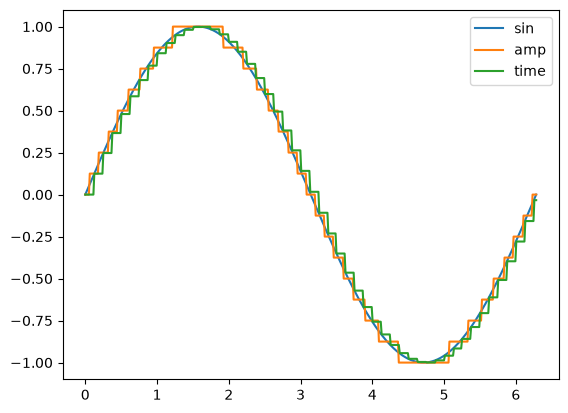

In [12]:
import numpy as np
import matplotlib.pyplot as plt
xs = np.linspace(0, np.pi * 2, 500)

plt.plot(xs, np.sin(xs), label="sin")
N = 8
plt.plot(xs, np.round(N*np.sin(xs))/N, label="amp")
plt.plot(xs, np.sin(np.floor(N*xs)/N), label="time")
plt.legend()

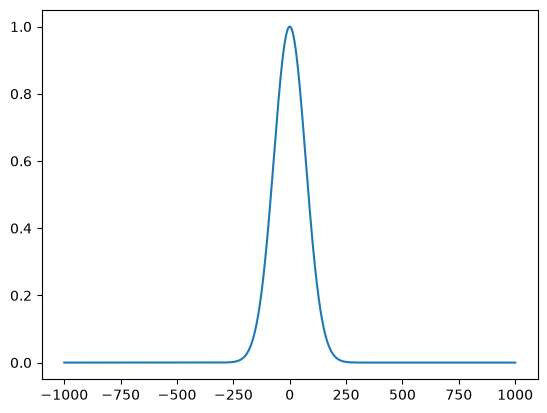

In [46]:
import numpy as np
import matplotlib.pyplot as plt
T = 1000
sample_rate = 100
ts = np.linspace(-T, T, T * 2 * sample_rate)
signal = np.exp(-(ts / T * 10)**2)

plt.plot(ts, signal)


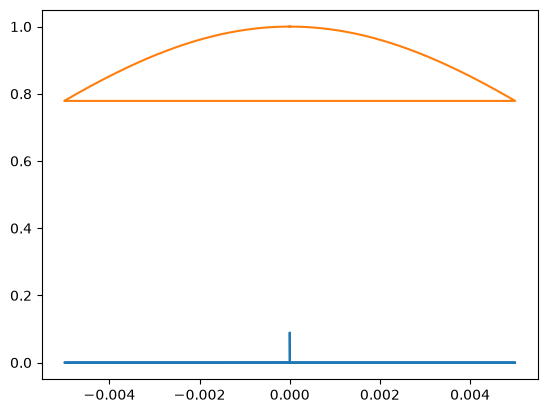

In [51]:
fft_output = np.fft.fft(signal) / len(signal)
frequencies = np.fft.fftfreq(len(signal), sample_rate)
closed = np.exp(-(frequencies / (1 / T * 10))**2)
plt.plot(frequencies, np.abs(fft_output))
plt.plot(frequencies, np.abs(closed))


In [ ]:
import sympy
t,w = sympy.symbols('t w', real=True)
sympy.fourier_transform(sympy.exp(-(t / T * 10)**2), t, w)



100*sqrt(pi)*exp(-10000*pi**2*w**2)